# BÀI 6. GIẢM SỐ MÀU TRONG ẢNH BẰNG THUẬT TOÁN K-MEANS

## Import thư viện

In [3]:
print("NguyenDucTinh - 6451071077")

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

%matplotlib inline

NguyenDucTinh - 6451071077


## Đọc và hiển thị ảnh

NguyenDucTinh - 6451071077


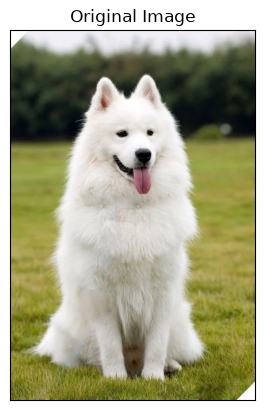

In [4]:
print("NguyenDucTinh - 6451071077")

# Đọc ảnh dog.png
image = Image.open('dog.png')

# Hiển thị ảnh
axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)

plt.title('Original Image')
plt.show()

## Chuyển ảnh thành mảng số

In [5]:
print("NguyenDucTinh - 6451071077")

# Chuyển ảnh thành mảng numpy
imarr = np.array(image)

# Lấy chiều cao và chiều rộng ảnh
rows = imarr.shape[0]
cols = imarr.shape[1]

# In thông tin ảnh
print("Kích thước ảnh:", imarr.shape)
print("Chiều cao ảnh:", rows)
print("Chiều rộng ảnh:", cols)

NguyenDucTinh - 6451071077
Kích thước ảnh: (800, 531, 3)
Chiều cao ảnh: 800
Chiều rộng ảnh: 531


## Chuẩn hóa và chuyển đổi dữ liệu

In [6]:
print("NguyenDucTinh - 6451071077")

# Đưa giá trị màu từ [0, 255] về [0, 1]
data = imarr / 255.0

# Chuyển mảng 3 chiều thành mảng 2 chiều
data = data.reshape(rows * cols, 3)

# Hiển thị kích thước dữ liệu
print("Kích thước dữ liệu sau khi chuyển đổi:", data.shape)

print("\n5 dòng dữ liệu đầu tiên:")
print(data[:5])

NguyenDucTinh - 6451071077
Kích thước dữ liệu sau khi chuyển đổi: (424800, 3)

5 dòng dữ liệu đầu tiên:
[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]


## Gom cụm màu bằng thuật toán k-Means

In [7]:
print("NguyenDucTinh - 6451071077")

# Khởi tạo mô hình KMeans với 32 cụm màu
kmeans = KMeans(
    n_clusters=32,
    max_iter=300,
    random_state=42
)

# Huấn luyện mô hình
kmeans.fit(data)

# Lấy màu đại diện của từng cụm
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

# Hiển thị kết quả
print("Đã hoàn thành quá trình gom cụm màu bằng KMeans")

print("Số cụm màu:", kmeans.n_clusters)

print("Kích thước tâm cụm:", kmeans.cluster_centers_.shape)

print("Giá trị Inertia:", kmeans.inertia_)

NguyenDucTinh - 6451071077
Đã hoàn thành quá trình gom cụm màu bằng KMeans
Số cụm màu: 32
Kích thước tâm cụm: (32, 3)
Giá trị Inertia: 548.5534222151931


## Khôi phục hình ảnh sau khi gom cụm

In [8]:
print("NguyenDucTinh - 6451071077")

# Chuyển mảng 2 chiều thành mảng 3 chiều như ảnh ban đầu
img_recolored = new_colors.reshape(imarr.shape)

# Hiển thị kích thước ảnh mới
print("Kích thước ảnh sau khi gom cụm:", img_recolored.shape)

NguyenDucTinh - 6451071077
Kích thước ảnh sau khi gom cụm: (800, 531, 3)


## Hiển thị và so sánh ảnh gốc với ảnh đã giảm màu

NguyenDucTinh - 6451071077


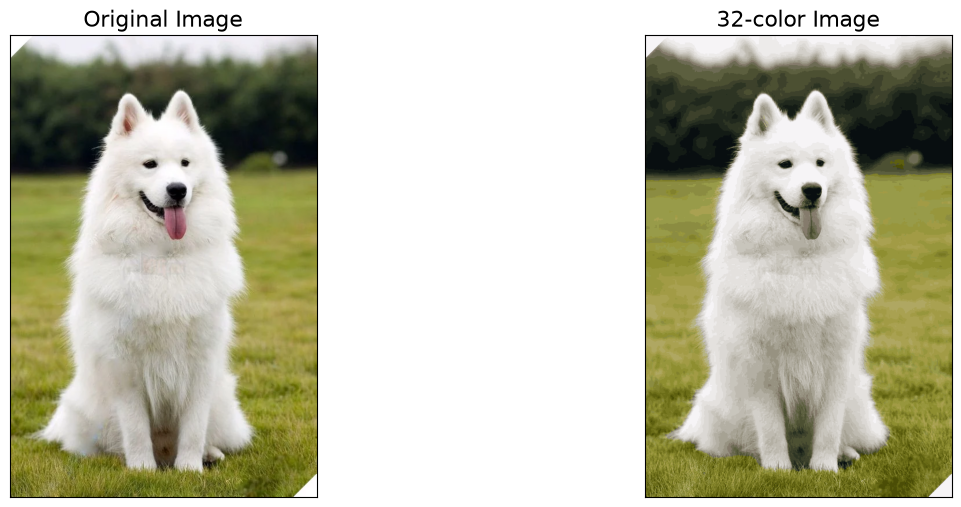

In [9]:
print("NguyenDucTinh - 6451071077")

# Tạo biểu đồ gồm 2 ảnh
fig, ax = plt.subplots(
    1, 2,
    figsize=(16, 6),
    subplot_kw=dict(xticks=[], yticks=[])
)

# Điều chỉnh khoảng cách giữa 2 ảnh
fig.subplots_adjust(wspace=0.05)

# Hiển thị ảnh gốc
ax[0].imshow(image)
ax[0].set_title('Original Image', size=16)

# Hiển thị ảnh đã giảm còn 32 màu
ax[1].imshow(img_recolored)
ax[1].set_title('32-color Image', size=16)

plt.show()

## Lưu hình ảnh kết quả xuống ổ đĩa

In [10]:
print("NguyenDucTinh - 6451071077")

# Chuyển giá trị màu từ [0, 1] về [0, 255]
img_recolored = img_recolored * 255

# Chuyển thành kiểu dữ liệu uint8
new_img = Image.fromarray(img_recolored.astype(np.uint8))

# Lưu ảnh kết quả
new_img.save('compressed_img2.png')

print("Đã lưu ảnh thành công: compressed_img2.png")

NguyenDucTinh - 6451071077
Đã lưu ảnh thành công: compressed_img2.png


## Kiểm tra kích thước file trước và sau khi giảm màu

In [11]:
print("NguyenDucTinh - 6451071077")

import os

# Lấy dung lượng ảnh gốc
original_size = os.path.getsize('dog.png')

# Lấy dung lượng ảnh sau khi xử lý
compressed_size = os.path.getsize('compressed_img2.png')

# Tính dung lượng giảm được
reduction = original_size - compressed_size

# Tính phần trăm giảm dung lượng
percentage = (reduction / original_size) * 100

print("Dung lượng ảnh gốc:", original_size, "bytes")

print("Dung lượng ảnh sau khi giảm màu:", compressed_size, "bytes")

print("Dung lượng giảm được:", reduction, "bytes")

print("Tỷ lệ giảm dung lượng:", round(percentage, 2), "%")

NguyenDucTinh - 6451071077
Dung lượng ảnh gốc: 47684 bytes
Dung lượng ảnh sau khi giảm màu: 149055 bytes
Dung lượng giảm được: -101371 bytes
Tỷ lệ giảm dung lượng: -212.59 %
